### Проведем разведочный анализ данных (EDA)

Загрузим библиотеки и данные

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv(r'C:\Users\Dasha\Desktop\Проектный практикум\train.csv')
test = pd.read_csv(r'C:\Users\Dasha\Desktop\Проектный практикум\test.csv')

Ознакомимся с данными

In [2]:
train.sample(10)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
54820,54820,28,140000,RENT,3.0,HOMEIMPROVEMENT,C,15000,12.87,0.10,Y,10,0
42495,42495,25,150000,MORTGAGE,9.0,HOMEIMPROVEMENT,C,8000,13.80,0.05,Y,2,0
20160,20160,27,44000,RENT,1.0,VENTURE,C,18000,14.26,0.41,Y,10,1
16629,16629,36,130000,MORTGAGE,2.0,HOMEIMPROVEMENT,D,25000,15.31,0.19,Y,16,0
33723,33723,26,30000,RENT,12.0,DEBTCONSOLIDATION,C,1200,14.27,0.04,N,2,0
18832,18832,27,45000,MORTGAGE,5.0,EDUCATION,B,6000,11.49,0.13,N,9,0
29203,29203,24,120000,MORTGAGE,3.0,DEBTCONSOLIDATION,A,7000,8.90,0.06,N,3,0
37192,37192,21,55000,OTHER,5.0,PERSONAL,C,16000,14.26,0.29,N,2,0
10558,10558,29,160000,MORTGAGE,2.0,PERSONAL,C,6000,13.98,0.04,Y,8,0
48980,48980,36,52000,RENT,2.0,MEDICAL,B,10000,10.62,0.19,N,13,0


In [3]:
test.sample(10)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
26796,85441,30,48000,OWN,4.0,MEDICAL,B,5000,10.62,0.10,N,10
8886,67531,22,31200,OWN,4.0,EDUCATION,D,6000,15.62,0.19,Y,4
6813,65458,22,55000,MORTGAGE,6.0,DEBTCONSOLIDATION,B,2000,11.11,0.04,N,4
32103,90748,27,31875,RENT,2.0,MEDICAL,C,7500,13.22,0.24,N,7
23647,82292,25,96000,MORTGAGE,9.0,HOMEIMPROVEMENT,B,4000,10.99,0.04,N,2
13944,72589,30,90000,RENT,6.0,DEBTCONSOLIDATION,B,20000,11.49,0.22,N,8
17976,76621,29,58000,RENT,13.0,HOMEIMPROVEMENT,B,10000,11.14,0.17,N,5
1525,60170,26,60000,MORTGAGE,6.0,PERSONAL,A,5000,5.99,0.08,N,4
11166,69811,28,30000,MORTGAGE,0.0,VENTURE,B,3000,11.11,0.10,N,10
36179,94824,27,48000,OWN,5.0,PERSONAL,B,4500,12.69,0.09,N,8


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          58645 non-null  int64  
 1   person_age                  58645 non-null  int64  
 2   person_income               58645 non-null  int64  
 3   person_home_ownership       58645 non-null  object 
 4   person_emp_length           58645 non-null  float64
 5   loan_intent                 58645 non-null  object 
 6   loan_grade                  58645 non-null  object 
 7   loan_amnt                   58645 non-null  int64  
 8   loan_int_rate               58645 non-null  float64
 9   loan_percent_income         58645 non-null  float64
 10  cb_person_default_on_file   58645 non-null  object 
 11  cb_person_cred_hist_length  58645 non-null  int64  
 12  loan_status                 58645 non-null  int64  
dtypes: float64(3), int64(6), object

In [5]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39098 entries, 0 to 39097
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          39098 non-null  int64  
 1   person_age                  39098 non-null  int64  
 2   person_income               39098 non-null  int64  
 3   person_home_ownership       39098 non-null  object 
 4   person_emp_length           39098 non-null  float64
 5   loan_intent                 39098 non-null  object 
 6   loan_grade                  39098 non-null  object 
 7   loan_amnt                   39098 non-null  int64  
 8   loan_int_rate               39098 non-null  float64
 9   loan_percent_income         39098 non-null  float64
 10  cb_person_default_on_file   39098 non-null  object 
 11  cb_person_cred_hist_length  39098 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.6+ MB


In [6]:
train.describe()

,id,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
count,58645.000000,58645.000000,5.864500e+04,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000
mean,29322.000000,27.550857,6.404617e+04,4.701015,9217.556518,10.677874,0.159238,5.813556,0.142382
std,16929.497605,6.033216,3.793111e+04,3.959784,5563.807384,3.034697,0.091692,4.029196,0.349445
min,0.000000,20.000000,4.200000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,0.000000
25%,14661.000000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000
50%,29322.000000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000
75%,43983.000000,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000
max,58644.000000,123.000000,1.900000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000,1.000000


In [7]:
test.describe()

,id,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,39098.000000,39098.000000,3.909800e+04,39098.000000,39098.000000,39098.000000,39098.000000,39098.000000
mean,78193.500000,27.566781,6.406046e+04,4.687068,9251.466188,10.661216,0.159573,5.830707
std,11286.764749,6.032761,3.795583e+04,3.868395,5576.254680,3.020220,0.091633,4.072157
min,58645.000000,20.000000,4.000000e+03,0.000000,700.000000,5.420000,0.000000,2.000000
25%,68419.250000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000
50%,78193.500000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000
75%,87967.750000,30.000000,7.588500e+04,7.000000,12000.000000,12.990000,0.210000,8.000000
max,97742.000000,94.000000,1.900000e+06,42.000000,35000.000000,22.110000,0.730000,30.000000


Выводы после первичного ознакомления с данными.

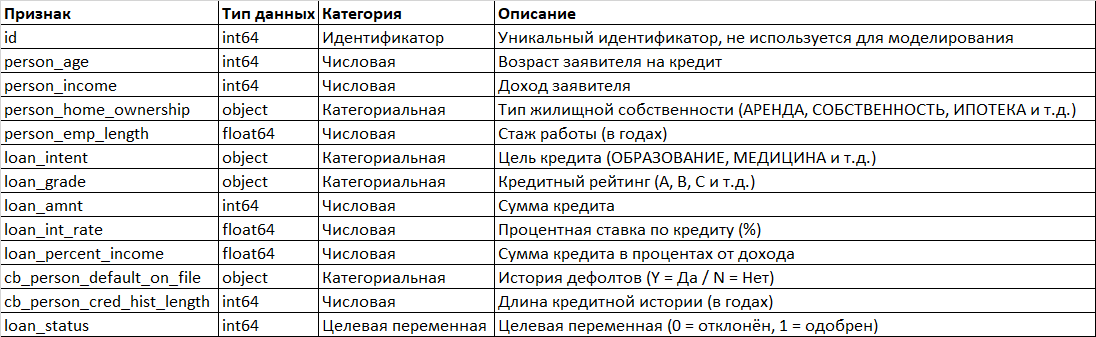

Размер и структура датасетов:

- Обучающий датасет содержит 58 645 записей с 13 столбцами, включая целевую переменную loan_status.

- Тестовый датасет состоит из 39 098 записей с 12 столбцами (без целевой переменной) и готов для прогнозирования.

Оба датасета содержат все ключевые атрибуты:

- Числовые признаки: person_age, person_income, person_emp_length, loan_amnt, loan_int_rate, loan_percent_income, cb_person_cred_hist_length.

- Категориальные признаки: person_home_ownership, loan_intent, loan_grade, cb_person_default_on_file.

- Целевая переменная (loan_status) является категориальной и отражает статус кредита.

Краткое описание статистики

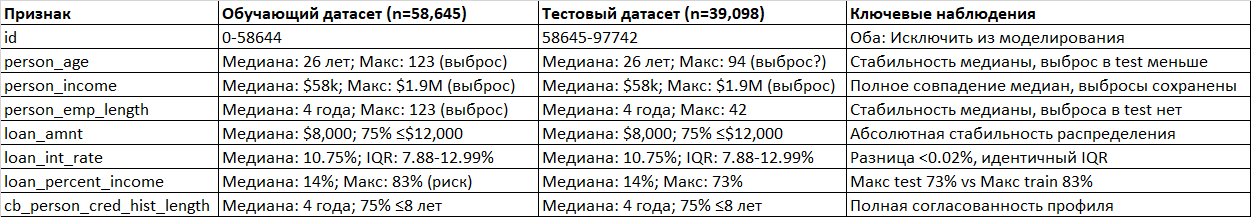


Ключевые наблюдения:

- Типичный профиль: Молодой заёмщик (26 лет) с доходом $58k, стажем 4 года, запрашивающий $8k (14% дохода) под 10.75%;

- Выбросы в возрасте (>100 лет) (train), доходе (>$1M) и стаже (>100 лет) (train и test);

- Высокий % кредита от дохода у части клиентов (до 83%);

- Сильный дисбаланс целевой переменной;

- Данные репрезентативны, тестовый набор пригоден для валидации моделей.

Проверим данные на пропуски

In [8]:
!pip install missingno

<Axes: >

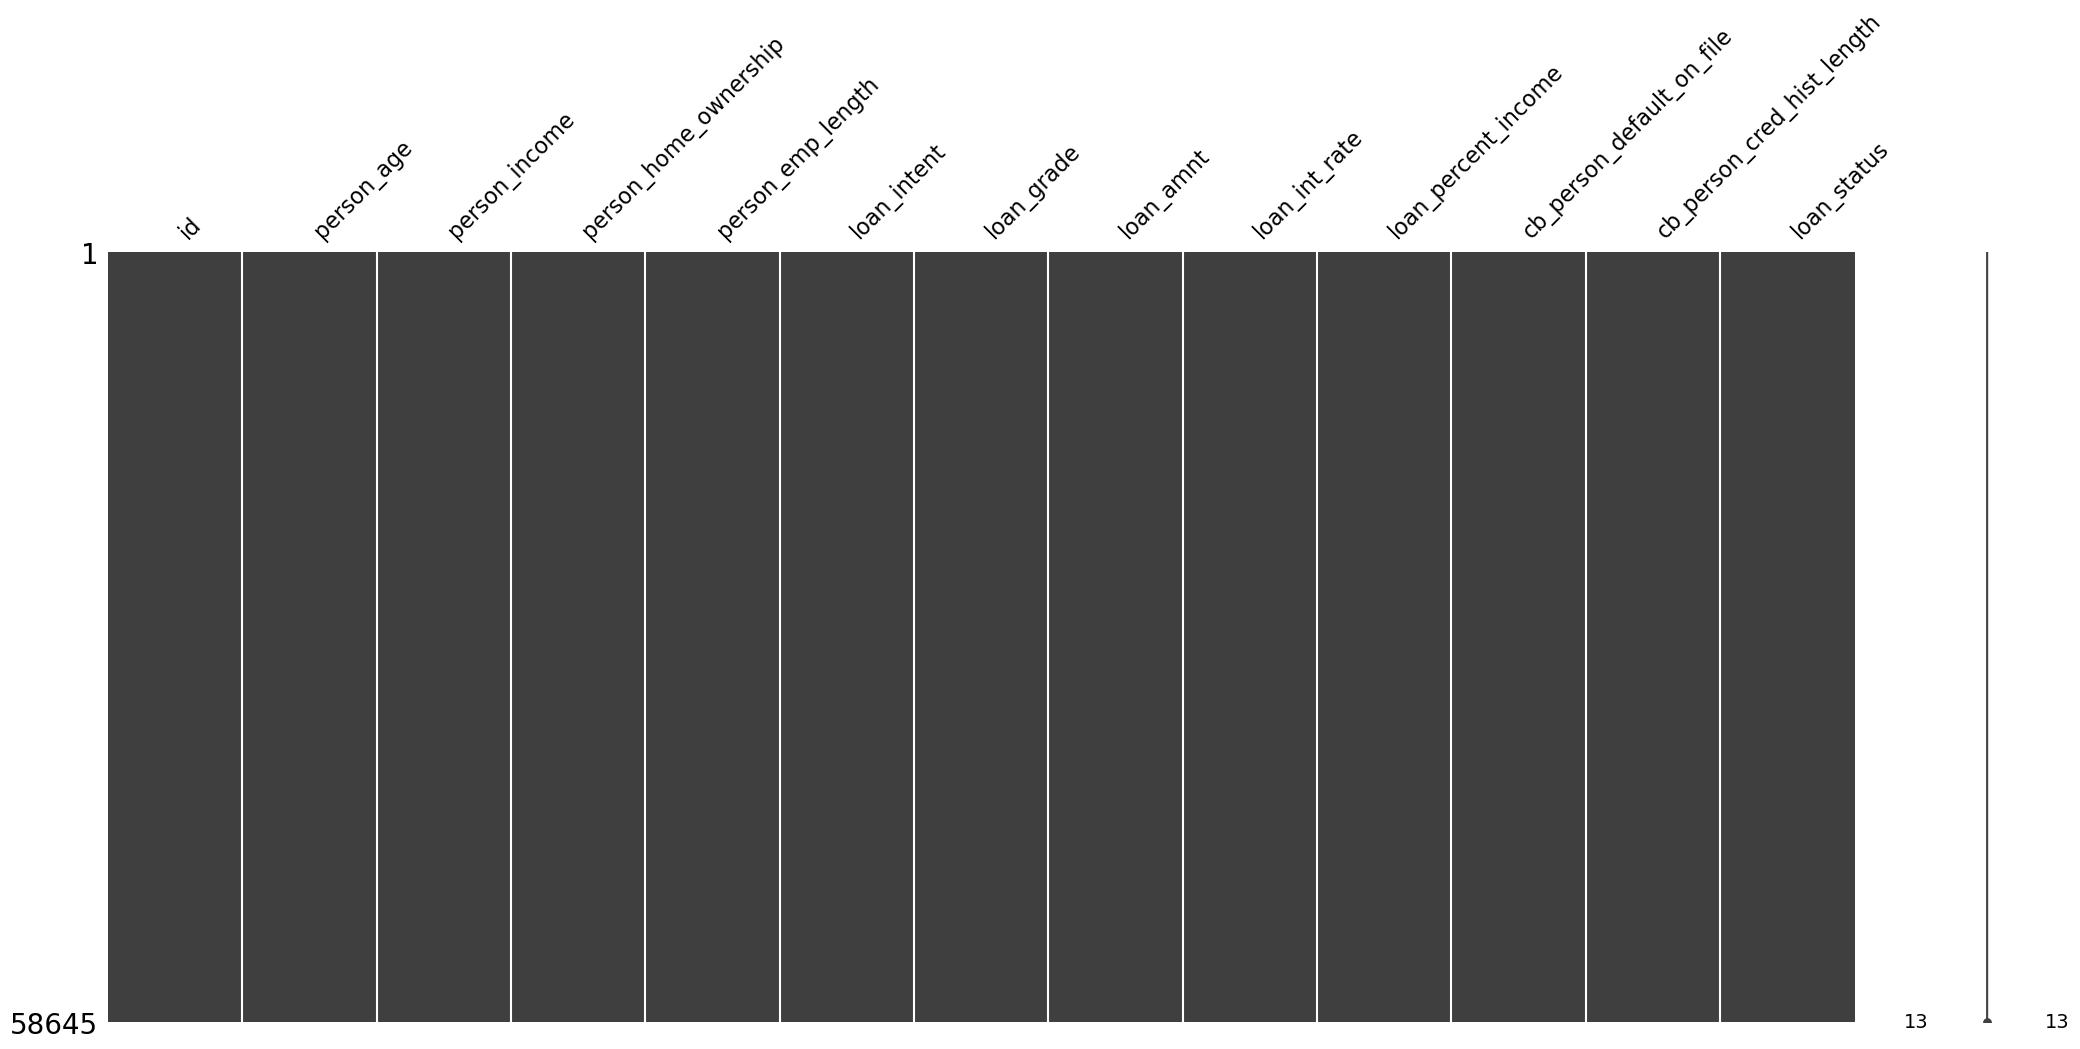

In [9]:
import missingno
missingno.matrix(train)

<Axes: >

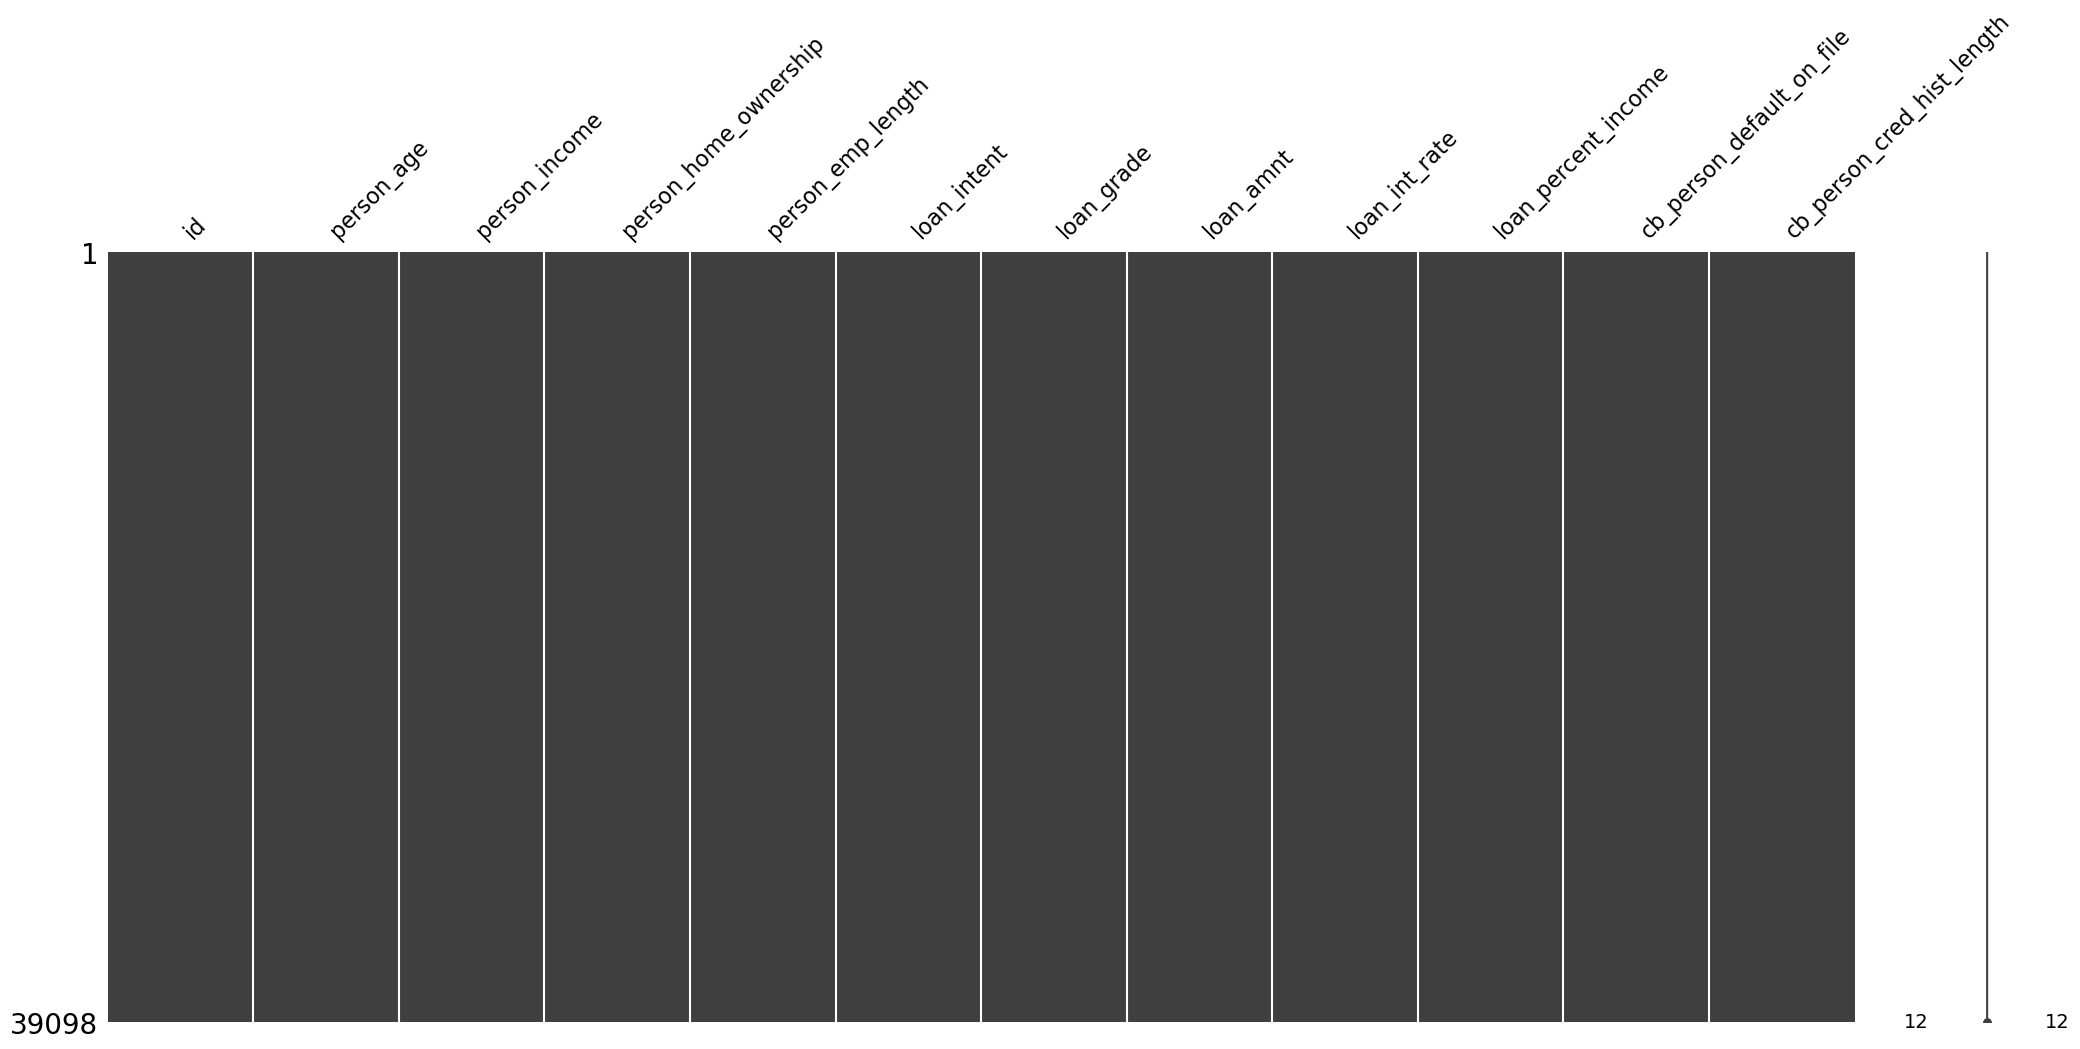

In [10]:
missingno.matrix(test)

In [11]:
train.isna()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58640,False,False,False,False,False,False,False,False,False,False,False,False,False
58641,False,False,False,False,False,False,False,False,False,False,False,False,False
58642,False,False,False,False,False,False,False,False,False,False,False,False,False
58643,False,False,False,False,False,False,False,False,False,False,False,False,False


In [12]:
test.isna()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
39093,False,False,False,False,False,False,False,False,False,False,False,False
39094,False,False,False,False,False,False,False,False,False,False,False,False
39095,False,False,False,False,False,False,False,False,False,False,False,False
39096,False,False,False,False,False,False,False,False,False,False,False,False


In [13]:
train.isnull().any().sum() # сколько признаков содержат неизвестные значения

0

In [14]:
test.isnull().any().sum() # сколько признаков содержат неизвестные значения

0

In [15]:
train.isnull().sum()[-13:] # cколько неизвестных значений содержит каждый признак

id                            0
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64

In [16]:
test.isnull().sum()[-12:] # cколько неизвестных значений содержит каждый признак

id                            0
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Проверим данные на наличие дубликатов

In [17]:
# Проверка на дубликаты train
print(f"Найдено дубликатов: {train.duplicated().sum()}")

Найдено дубликатов: 0


In [18]:
# Проверка на дубликаты test
print(f"Найдено дубликатов: {test.duplicated().sum()}")

Найдено дубликатов: 0


Выводы после проверки данных на пропуски и дубликаты.

Обучающий и тестовый датасеты демонстрируют высокое качество: отсутствуют пропущенные значения и дубликаты.

Углубимся в изучение данных


🎯 АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ: loan_status


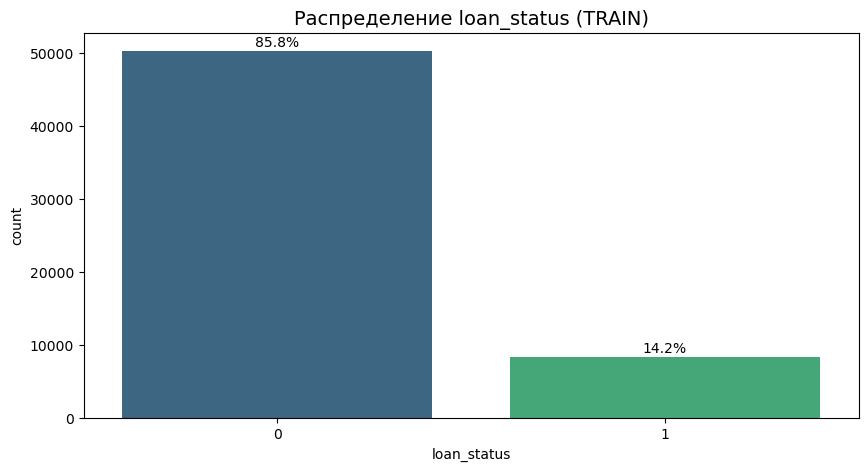


🔢 АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ (7):


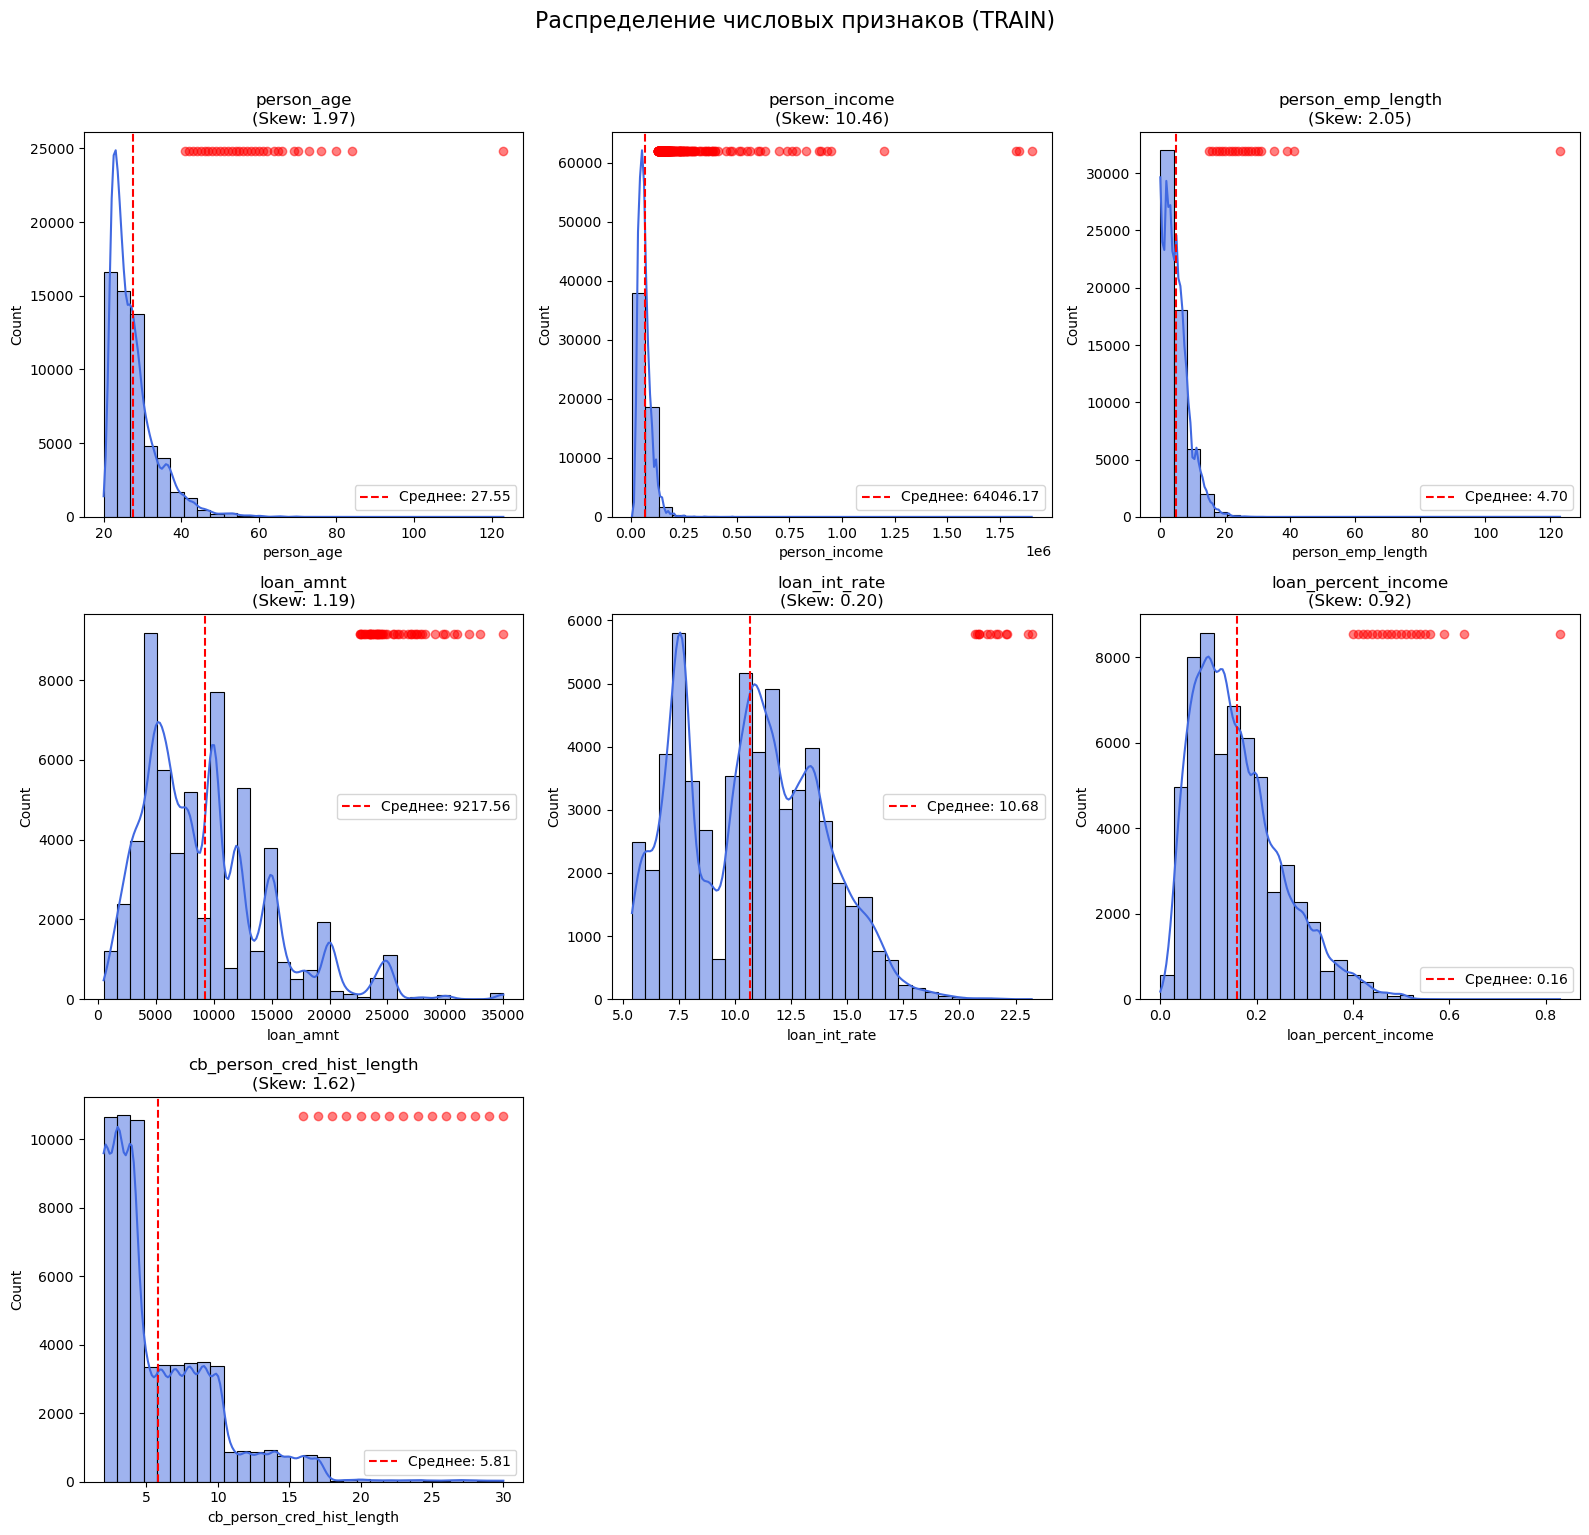


📌 АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ (4):
🔎 Уникальные значения:


,Уникальных значений
cb_person_default_on_file,2
person_home_ownership,4
loan_intent,6
loan_grade,7


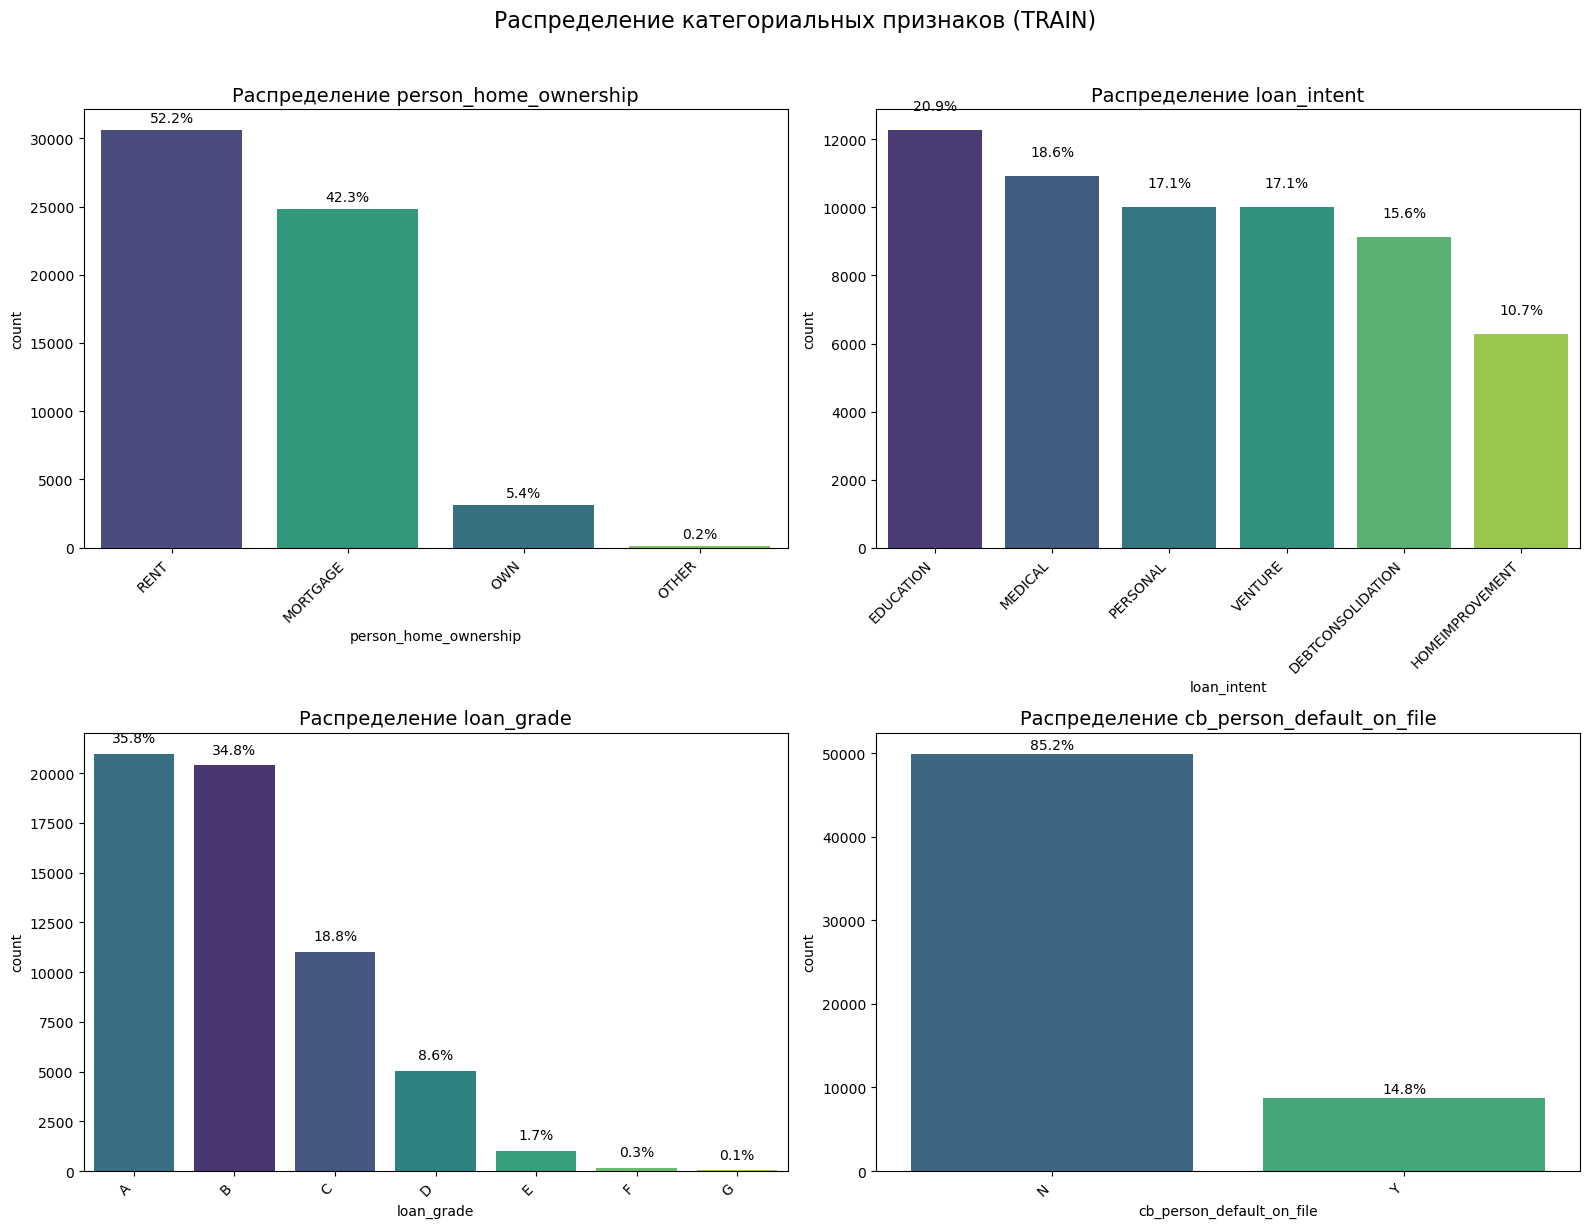


📈 СВЯЗЬ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ С ЦЕЛЕВОЙ ПЕРЕМЕННОЙ


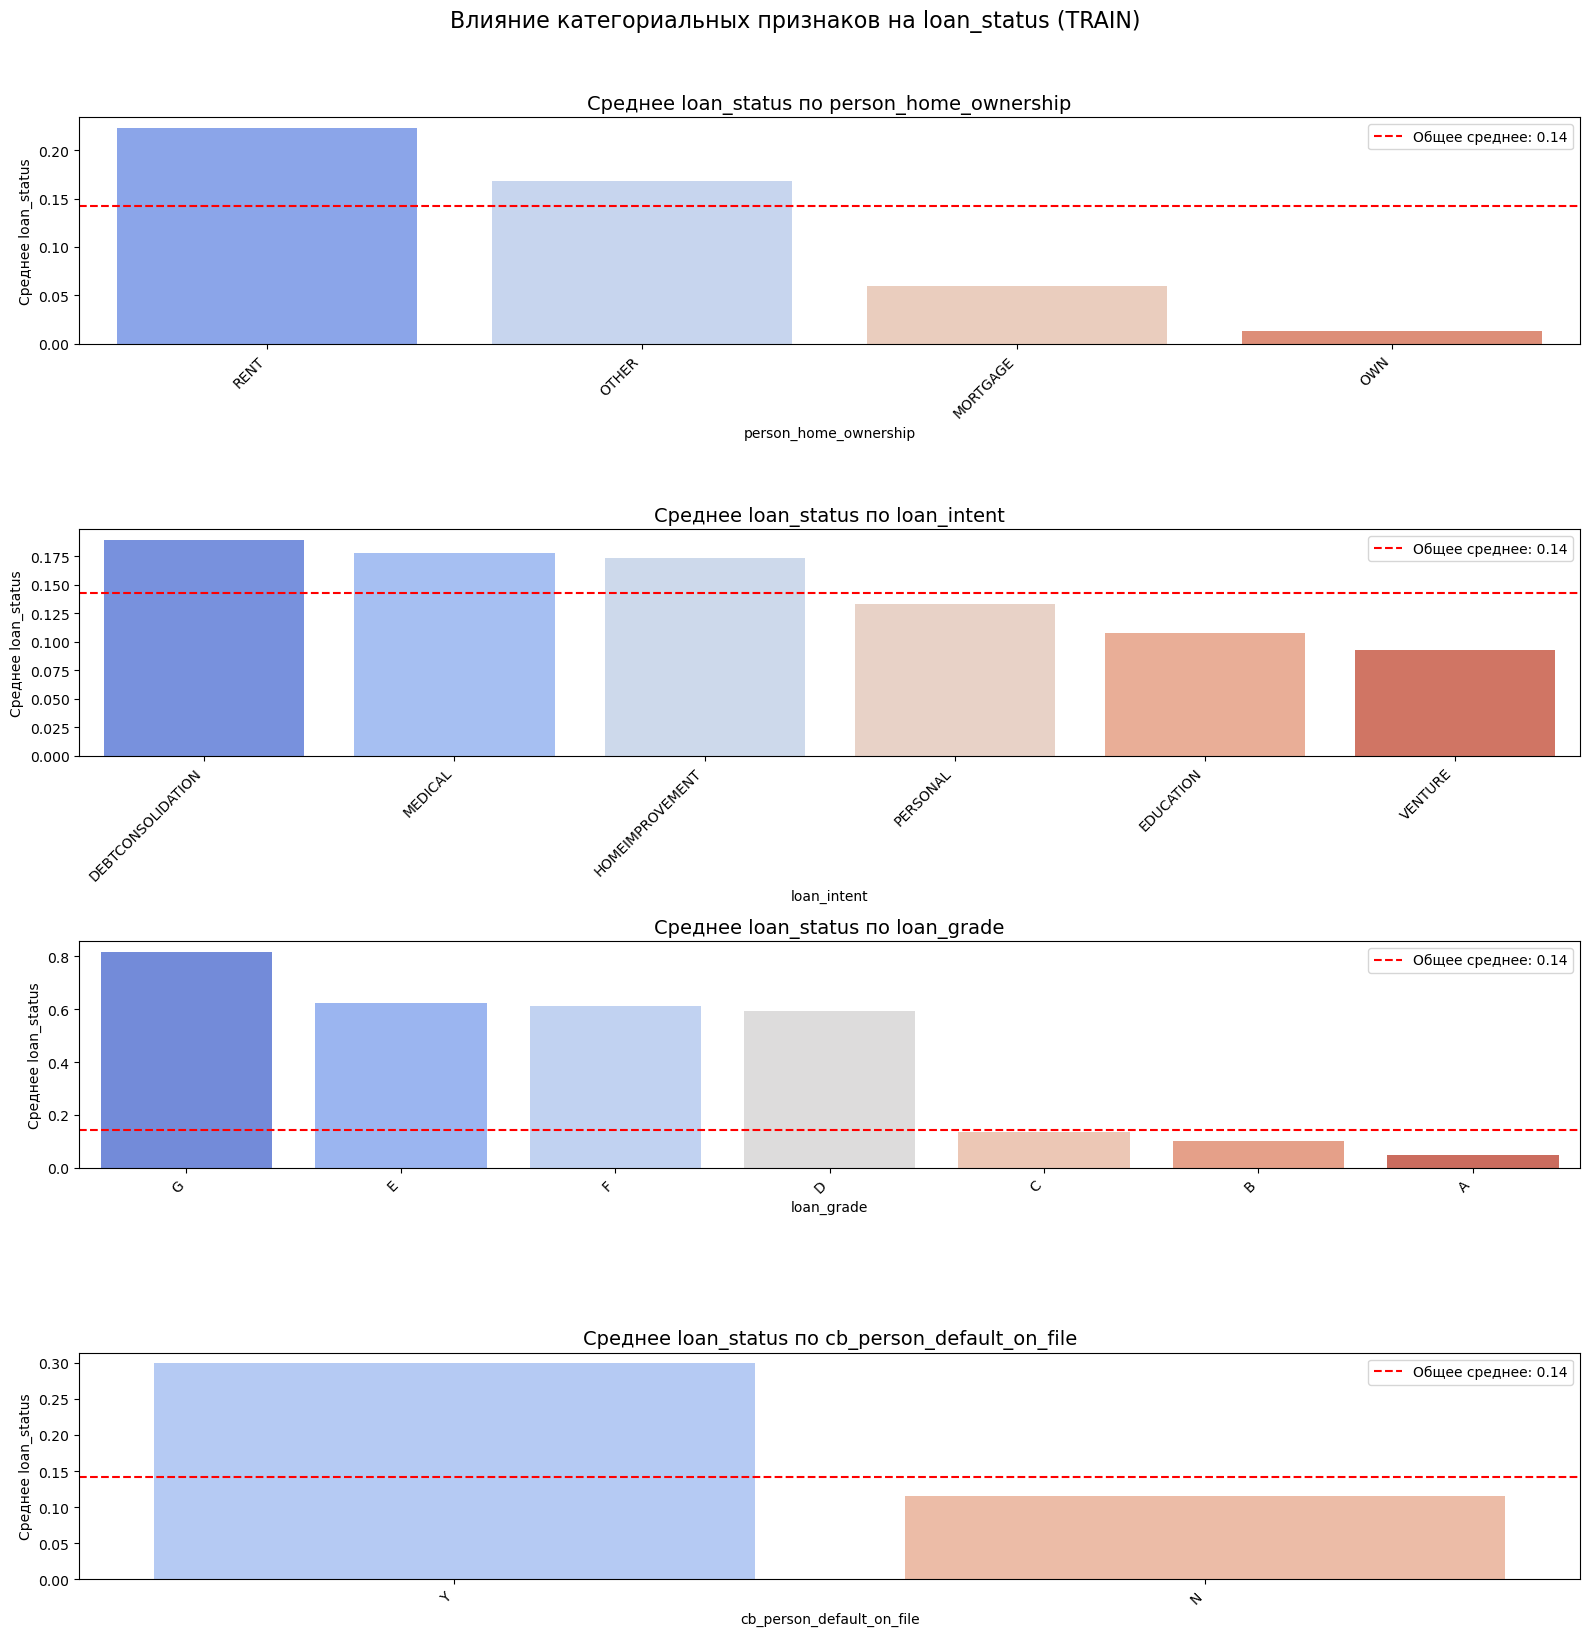


📊 МАТРИЦА КОРРЕЛЯЦИЙ (числовые признаки)


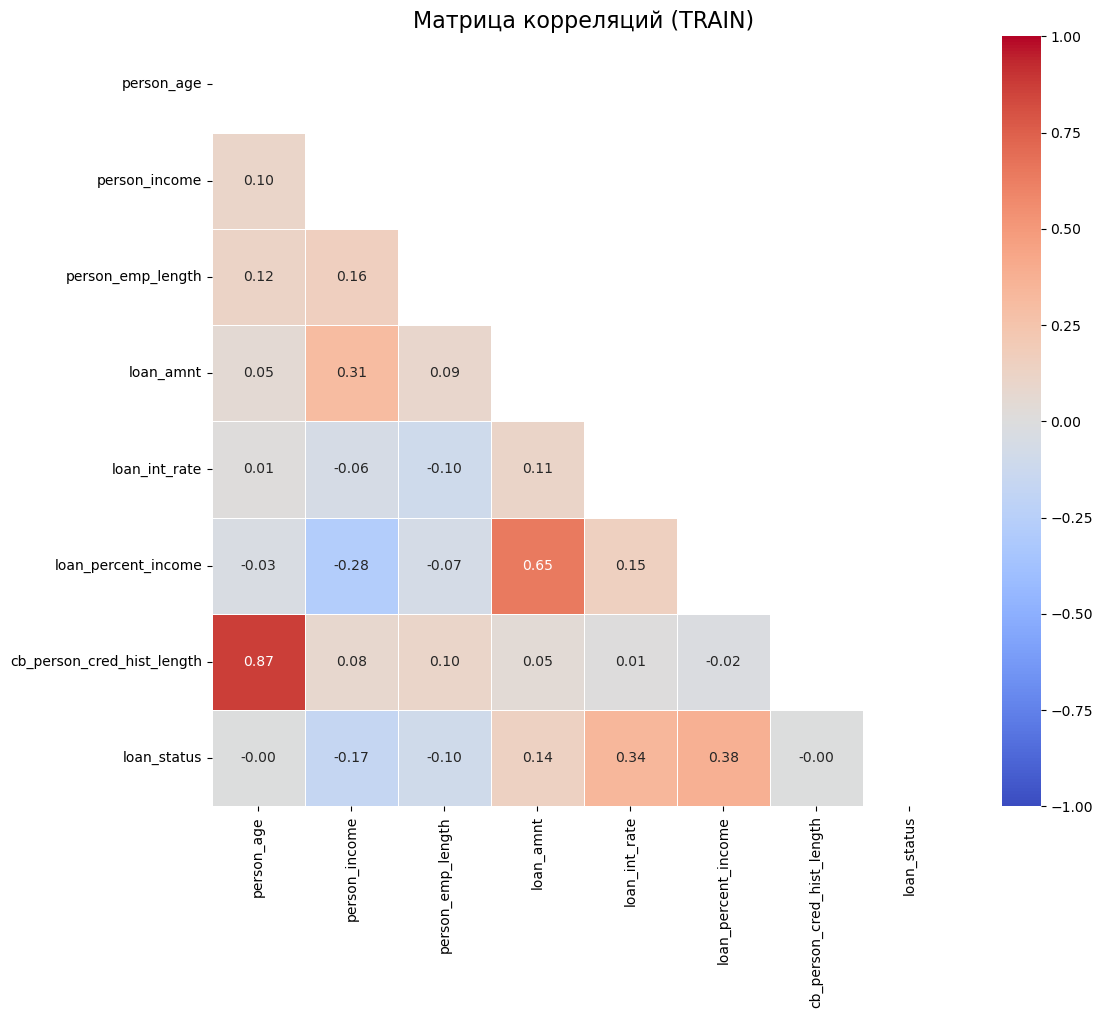


🔝 Топ корреляций с целевой переменной:


,Корреляция
loan_percent_income,0.378280
loan_int_rate,0.338948
person_income,-0.169956
loan_amnt,0.144982
person_emp_length,-0.100428
cb_person_cred_hist_length,-0.003030
person_age,-0.001130



✅ EDA ЗАВЕРШЕН ДЛЯ ДАТАСЕТА (TRAIN)

🔢 АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ (7):


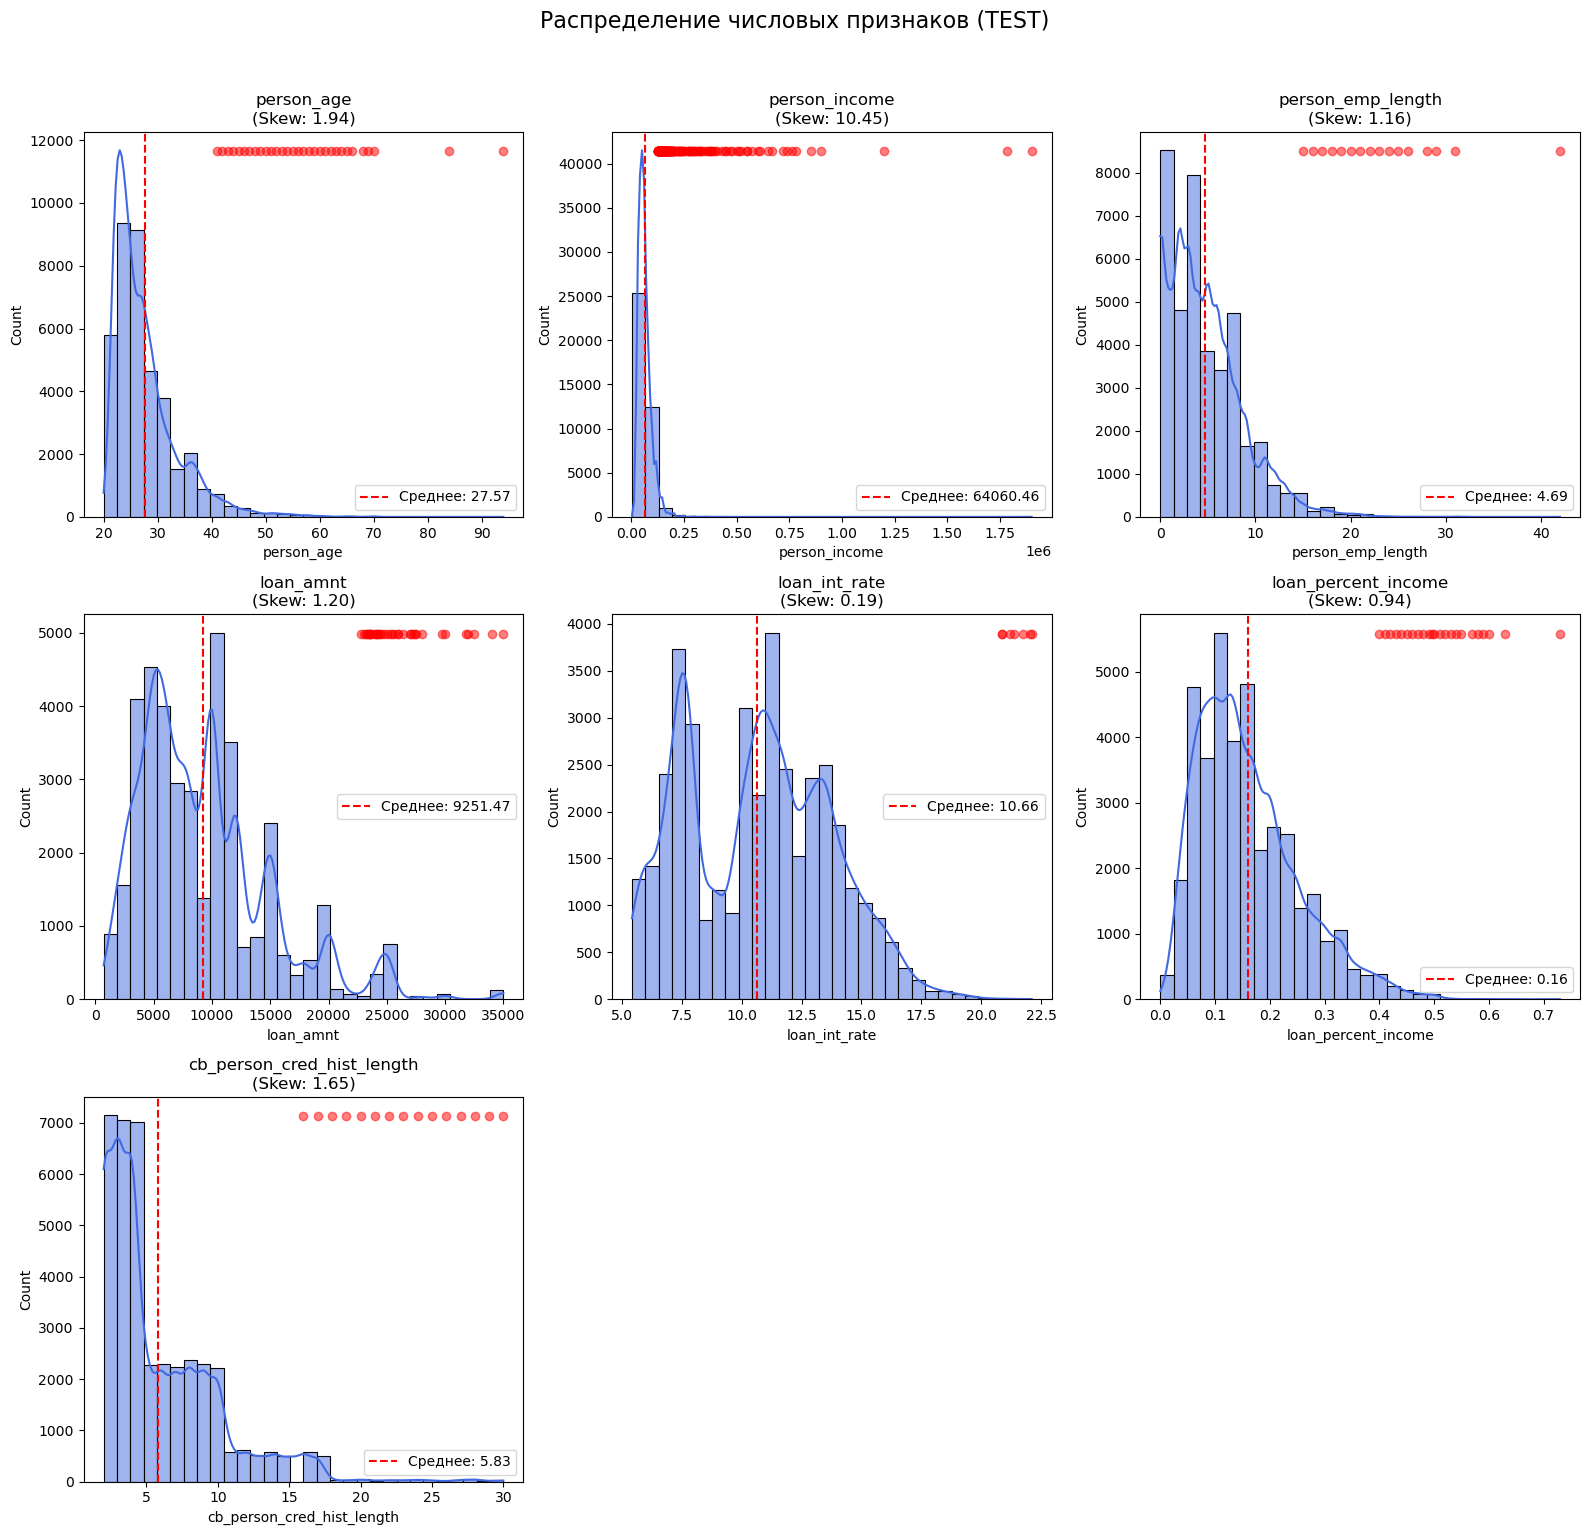


📌 АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ (4):
🔎 Уникальные значения:


,Уникальных значений
cb_person_default_on_file,2
person_home_ownership,4
loan_intent,6
loan_grade,7


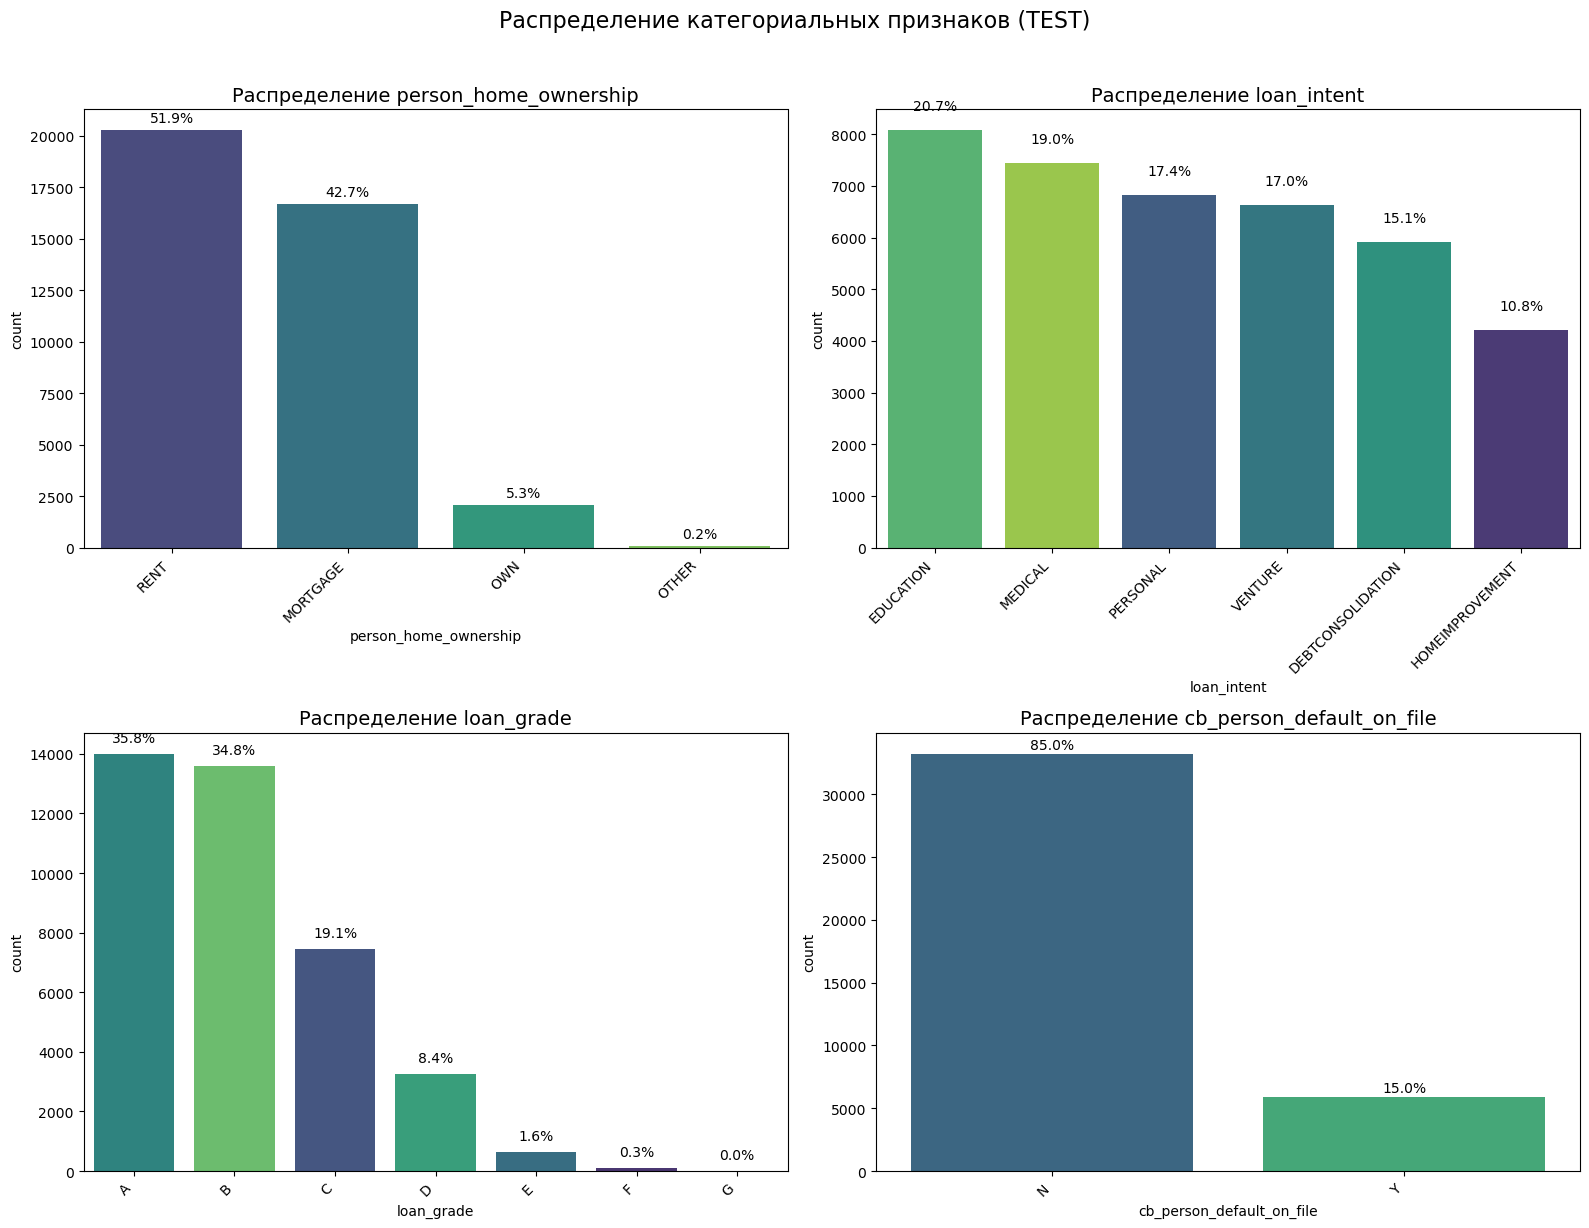


✅ EDA ЗАВЕРШЕН ДЛЯ ДАТАСЕТА (TEST)


In [19]:
def basic_eda(train, target_col='loan_status', dataset_name=''):
    """
    Проводит базовый разведочный анализ (EDA) для датасета с поддержкой train/test

    Параметры:
    train (pd.DataFrame): Исходный датасет
    target_col (str): Название целевой переменной (необязательно для test)
    dataset_name (str): Название датасета для заголовков
    """
    # Копируем данные, чтобы не изменять оригинал
    train = train.copy()

    # Исключаем столбец 'id' из анализа
    if 'id' in train.columns:
        train = train.drop(columns=['id'])

    # Заголовок с именем датасета
    dataset_title = f" ({dataset_name})" if dataset_name else ""

    # 3. Анализ целевой переменной (только если она присутствует)
    if target_col in train.columns:
        print("\n" + "="*80)
        print(f"🎯 АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ: {target_col}")
        print("="*80)

        # Распределение
        plt.figure(figsize=(10, 5))
        if train[target_col].nunique() <= 5:  # Категориальная
            target_counts = train[target_col].value_counts(normalize=True)
            # ИСПРАВЛЕНИЕ: добавлен hue и legend=False
            ax = sns.countplot(
                data=train,
                x=target_col,
                hue=target_col,  # Добавлено
                palette='viridis',
                legend=False     # Добавлено
            )
            plt.title(f'Распределение {target_col}{dataset_title}', fontsize=14)
            for p in ax.patches:
                height = p.get_height()
                ax.text(p.get_x() + p.get_width()/2., height + len(train)*0.01,
                        f'{height/len(train):.1%}', ha='center')
        else:  # Числовая
            sns.histplot(train[target_col], kde=True, color='royalblue')
            plt.title(f'Распределение {target_col}{dataset_title}', fontsize=14)
            plt.axvline(train[target_col].mean(), color='red', linestyle='--',
                        label=f'Среднее: {train[target_col].mean():.2f}')
            plt.legend()
        plt.show()


    # 4. Анализ числовых признаков (исключая целевую)
    num_cols = train.select_dtypes(include=['int64', 'float64']).columns
    if target_col in num_cols:
        num_cols = num_cols.drop(target_col)

    if len(num_cols) > 0:
        print("\n" + "="*80)
        print(f"🔢 АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ ({len(num_cols)}):")
        print("="*80)


        # Визуализация распределений
        n_cols = 3
        n_rows = int(np.ceil(len(num_cols) / n_cols))
        plt.figure(figsize=(16, n_rows * 5))
        plt.suptitle(f'Распределение числовых признаков{dataset_title}', fontsize=16, y=1.02)

        for i, col in enumerate(num_cols, 1):
            plt.subplot(n_rows, n_cols, i)

            # Гистограмма + KDE
            sns.histplot(train[col], kde=True, color='royalblue', bins=30)

            # Выбросы (красные точки)
            q1 = train[col].quantile(0.25)
            q3 = train[col].quantile(0.75)
            iqr = q3 - q1
            outliers = train[(train[col] < q1 - 1.5*iqr) | (train[col] > q3 + 1.5*iqr)][col]
            if not outliers.empty:
                y_max = plt.ylim()[1] * 0.95
                for val in outliers.unique():
                    plt.plot(val, y_max, 'ro', alpha=0.5)

            plt.title(f'{col}\n(Skew: {train[col].skew():.2f})', fontsize=12)
            plt.axvline(train[col].mean(), color='red', linestyle='--',
                        label=f'Среднее: {train[col].mean():.2f}')
            plt.legend()

        plt.tight_layout()
        plt.show()

    # 5. Анализ категориальных признаков
    cat_cols = train.select_dtypes(include=['object', 'category']).columns

    if len(cat_cols) > 0:
        print("\n" + "="*80)
        print(f"📌 АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ({len(cat_cols)}):")
        print("="*80)

        # Уникальные значения
        print("🔎 Уникальные значения:")
        unique_counts = {}
        for col in cat_cols:
            unique_counts[col] = train[col].nunique()
        unique_counts = pd.Series(unique_counts).sort_values()
        display(unique_counts.to_frame('Уникальных значений'))

        # Визуализация
        n_cols = 2
        n_rows = int(np.ceil(len(cat_cols) / n_cols))
        plt.figure(figsize=(16, n_rows * 6))
        plt.suptitle(f'Распределение категориальных признаков{dataset_title}', fontsize=16, y=1.02)

        for i, col in enumerate(cat_cols, 1):
            plt.subplot(n_rows, n_cols, i)

            # Топ-10 категорий
            top_cats = train[col].value_counts().nlargest(10)
            # ИСПРАВЛЕНИЕ: добавлен hue и legend=False
            ax = sns.countplot(
                data=train,
                x=col,
                hue=col,        # Добавлено
                order=top_cats.index,
                palette='viridis',
                legend=False    # Добавлено
            )
            plt.title(f'Распределение {col}', fontsize=14)
            plt.xticks(rotation=45, ha='right')

            # Аннотации
            total = len(train)
            for p in ax.patches:
                height = p.get_height()
                ax.text(p.get_x() + p.get_width()/2., height + total*0.01,
                        f'{height/total:.1%}', ha='center')

        plt.tight_layout()
        plt.show()

        # Связь с целевой переменной (если она есть)
        if target_col in train.columns and train[target_col].nunique() <= 5:
            print("\n" + "="*80)
            print(f"📈 СВЯЗЬ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ С ЦЕЛЕВОЙ ПЕРЕМЕННОЙ")
            print("="*80)

            plt.figure(figsize=(16, len(cat_cols) * 4))
            plt.suptitle(f'Влияние категориальных признаков на {target_col}{dataset_title}', fontsize=16, y=1.02)

            for i, col in enumerate(cat_cols, 1):
                plt.subplot(len(cat_cols), 1, i)

                # Расчет среднего значения целевой по категориям
                grouped = train.groupby(col)[target_col].mean().sort_values(ascending=False)

                # Визуализация
                # ИСПРАВЛЕНИЕ: добавлен hue и legend=False
                sns.barplot(
                    x=grouped.index,
                    y=grouped.values,
                    hue=grouped.index,  # Добавлено
                    palette='coolwarm',
                    legend=False        # Добавлено
                )
                plt.axhline(
                    train[target_col].mean(),
                    color='red',
                    linestyle='--',
                    label=f'Общее среднее: {train[target_col].mean():.2f}'
                )
                plt.title(f'Среднее {target_col} по {col}', fontsize=14)
                plt.ylabel(f'Среднее {target_col}')
                plt.xticks(rotation=45, ha='right')
                plt.legend()

            plt.tight_layout()
            plt.show()

    # 6. Корреляции (только для числовых признаков и если есть целевая)
    if len(num_cols) > 1 and target_col in train.columns:
        print("\n" + "="*80)
        print("📊 МАТРИЦА КОРРЕЛЯЦИЙ (числовые признаки)")
        print("="*80)

        # Выбираем только числовые + целевая
        corr_cols = num_cols.tolist() + [target_col]
        corr = train[corr_cols].corr()

        plt.figure(figsize=(12, 10))
        mask = np.triu(np.ones_like(corr, dtype=bool))
        sns.heatmap(
            corr,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            vmin=-1,
            vmax=1,
            linewidths=0.5
        )
        plt.title(f'Матрица корреляций{dataset_title}', fontsize=16)
        plt.show()

        # Топ корреляций с целевой
        target_corr = corr[target_col].drop(target_col).sort_values(key=abs, ascending=False)
        print("\n🔝 Топ корреляций с целевой переменной:")
        display(target_corr.head(10).to_frame('Корреляция'))

    print("\n" + "="*80)
    print(f"✅ EDA ЗАВЕРШЕН ДЛЯ ДАТАСЕТА{dataset_title}")
    print("="*80)

# Использованиe:
# Для train датасета:
basic_eda(train, target_col='loan_status', dataset_name='TRAIN')

# Для test датасета:
basic_eda(test, target_col=None, dataset_name='TEST')

Выводы после разведочного анализа целевой переменной, числовых и категориальных признаков.

1. Анализ целевой переменной (loan_status)

  В обучающей выборке наблюдается явный дисбаланс в распределении переменной loan_status. Этот дисбаланс может искажать процесс обучения модели.

2. Анализ числовых признаков
* 2.1. Согласованность распределений

  - Обучающая и тестовая выборки демонстрируют практически идентичные распределения числовых признаков. Это повышает способность модели к обобщению.
* 2.2. Форма и разброс распределений

  - Некоторые переменные (например, loan_amnt, loan_int_rate) имеют длинные хвосты или мультимодальные распределения. Это свидетельствует о наличии подгрупп или различных уровней процентных ставок.
* 2.3. Анализ асимметрии
  - Признаки person_age, person_emp_length, cb_person_cred_hist_length, loan_amnt, loan_percent_income, person_income имеют значительную асимметрию (|коэффициент| > 0.5). Их смещенные распределения могут выиграть от преобразований. Устранение асимметрии важно, так как она может влиять на производительность алгоритмов.

* 2.4. Наблюдения по конкретным признакам
  - Возраст (person_age), доход (person_income), стаж работы (person_emp_length): концентрируются в нижних диапазонах; наличие экстремальных значений усиливает асимметрию.
  - Сумма кредита (loan_amnt), процентная ставка (loan_int_rate), доля дохода (loan_percent_income), длина кредитной истории (cb_person_cred_hist_length): демонстрируют мультимодальные или асимметричные распределения, указывая на разнообразие кредитных продуктов и профилей заемщиков.

* 2.5. Корреляционный анализ
  - Корреляционная структура между обучающей и тестовой выборками стабильна, что указывает на отсутствие сдвига данных и повышает уверенность в модели.
  - Сильные корреляции:

    person_age и cb_person_cred_hist_length: высокая положительная (+0.87). Люди старшего возраста обычно имеют более длинную кредитную историю.

    loan_percent_income и loan_amnt: положительная (+0.6). Большие суммы кредитов составляют большую долю дохода заемщика.

3. Анализ категориальных признаков
* 3.1. Распределения
  - Кредитный рейтинг (loan_grade, A-G): Сильно смещенное распределение. Классы A, B, C составляют большинство; D-G встречаются редко.
  - Цель кредита (loan_intent): Распределение практически равномерное (6 категорий).
  - Тип жилья (person_home_ownership): Резко смещенное распределение. Доминируют RENT (Аренда) и MORTGAGE (Ипотека); остальные категории минимальны.
  - История дефолтов (cb_person_default_on_file): Бинарный признак (N - нет дефолта, Y - были дефолты). Сильный дисбаланс: N: ~85%;  Y: ~15%
* 3.2. Взаимосвязь с целевой переменной (loan_status)
  - Тип жилья (person_home_ownership):

    Чаще одобряются: RENT (Арендаторы).
    
    Чаще отклоняются: OWN (Владельцы), MORTGAGE (Ипотечники).
  - Цель кредита (loan_intent):

    Чаще одобряются: кредиты на долговую консолидацию (DEBTCONSOLIDATION), ремонт жилья (HOMEIMPROVEMENT), медицинские нужды (MEDICAL).

    Чаще отклоняются: кредиты на образование (EDUCATION), бизнес-цели (VENTURE), личные нужды (PERSONAL).
* Кредитный рейтинг (loan_grade):
  - Парадоксальная закономерность: кредиты с низким рейтингом (D–G) одобряются чаще ожидаемого.
  - Возможная причина: стратегия кредитования, ориентированная на рискованные займы с высокими процентами.
* История дефолтов (cb_person_default_on_file):
  - Неожиданный вывод: Заявители с дефолтами в анамнезе (Y) имеют более высокую вероятность одобрения, несмотря на то, что дефолт обычно считается негативным фактором.